### Evaluation

Notebook to run evaulation on test data

- use daily provided data (evaluation period of competition)

Data: "../data/evaluation/[met_nowcast_daily, met_forecast_daily, wind_power]"


In [1]:
import os
import sys

sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from jax import random
from numpyro.infer import Predictive
import arviz as az

from validate_example import validate_forecast
from data_processing.load import load_evaluation_data
from data_processing.utils import load_scaler_params, load_checkpoint
from models.model import model_mw_gamma

In [2]:
# TODO
# DONE load evaluation input
# fix column names
# DONE calculate capacity factor
# DONE load model from checkpoint
# DONE (select bidding zone)
# DONE evaluate model for (all) bidding zone
# multiply with available capacity to get absolute generated power
# DONE save median, q025 and q975 in a CSV
# DONE verify format with verify_example.py
# check how good forecast was afterwards (in competition one day later)

In [3]:
bid_zone = "ELSPOT NO1"
date = "2025-06-09"

In [4]:
bid_zones = ["ELSPOT NO1", "ELSPOT NO2", "ELSPOT NO3", "ELSPOT NO4"]
bid_zones = [bz.replace(" ", "_") for bz in bid_zones]

### Load params and evaluation data


In [5]:
# Load scaler params (same for all models in this bid zone)
scaler_data = load_scaler_params(bid_zone=bid_zone, dir_path="../checkpoints")

# Load evaluation data using training scaler params
eval_data = load_evaluation_data(
    date=date,
    scaler_params=scaler_data["scaler_params"],
    site_scaler_params=scaler_data["site_scaler_params"],
    bid_zone=bid_zone,
)

Loaded scaler parameters for ELSPOT NO1
  Saved at: 2025-11-20 12:21:12
  Split time: 2025-01-01 00:00:00+01:00
Loading evaluation data for 2025-06-09 in zone ELSPOT NO1


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Evaluation data shape: X=(24, 6, 6), Y_gen=(24,)


In [6]:
# Load trained model checkpoint, bidding zone specific!
checkpoint = load_checkpoint(file_name="model_mw_gamma_2025-11-13_10-56-50_gen")

Loading specified checkpoint: ../checkpoints/model_mw_gamma_2025-11-13_10-56-50_gen.pkl


### Run inference


In [7]:
_, rng_key_predict = random.split(checkpoint["rng_key"])

predictive = Predictive(model_mw_gamma, checkpoint["samples"])(
    rng_key_predict, eval_data["X_eval"]
)

preds = predictive["Y"]
mu = predictive["mu"]
alpha = predictive["alpha"]

median = np.percentile(preds, 50, axis=0)
q025 = np.percentile(preds, 2.5, axis=0)
q975 = np.percentile(preds, 97.5, axis=0)
hdi = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)

### Save predictions as CSV


In [8]:
forecast = pd.DataFrame(
    index=eval_data["index"],
    columns=bid_zones,
    data=0,
)
forecast_extended = [
    pd.DataFrame(
        index=eval_data["index"],
        columns=["median", "hdi_lower", "hdi_upper"],
        data=0,
    )
    for i in range(len(bid_zones))
]

In [9]:
for i, bz in enumerate(bid_zones):

    # Load bid zone specific trained model checkpoint
    checkpoint = load_checkpoint(
        file_name="model_mw_gamma_2025-11-13_10-56-50_gen"
    )  # TODO make it bid zone specific

    # Run inference
    _, rng_key_predict = random.split(checkpoint["rng_key"])

    predictive = Predictive(model_mw_gamma, checkpoint["samples"])(
        rng_key_predict, eval_data["X_eval"]
    )

    preds = predictive["Y"]
    median = np.percentile(preds, 50, axis=0)
    hdis = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)
    hdi_lower, hdi_upper = hdis[:, 0], hdis[:, 1]

    forecast[bz] = median
    forecast_extended[i][["median", "hdi_lower", "hdi_upper"]] = np.column_stack(
        [median, hdi_lower, hdi_upper]
    )

    break  # TODO no checkpoints for other bid zones so far

Loading specified checkpoint: ../checkpoints/model_mw_gamma_2025-11-13_10-56-50_gen.pkl


In [10]:
# Save predictions to CSV
data_folder = f"../data/evaluation/{date}"
file_path = f"{data_folder}/forecast.csv"
if not os.path.exists(data_folder):
    os.makedirs(data_folder)
forecast.to_csv(file_path)

In [11]:
forecast

,ELSPOT_NO1,ELSPOT_NO2,ELSPOT_NO3,ELSPOT_NO4
time,,,,
2025-06-08 11:00:00+02:00,26.944101,0,0,0
2025-06-08 12:00:00+02:00,31.097534,0,0,0
2025-06-08 13:00:00+02:00,29.494013,0,0,0
2025-06-08 14:00:00+02:00,41.107994,0,0,0
2025-06-08 15:00:00+02:00,62.880497,0,0,0
2025-06-08 16:00:00+02:00,36.750317,0,0,0
2025-06-08 17:00:00+02:00,44.219883,0,0,0
2025-06-08 18:00:00+02:00,20.523863,0,0,0
2025-06-08 19:00:00+02:00,21.851116,0,0,0


In [12]:
len(forecast["ELSPOT_NO1"])

24

In [13]:
# Validate format
df = validate_forecast(file_path)

SchemaError: DataFrameSchema 'ForecastSchema' failed series or dataframe validator 0: <Check check_full_day>

### Metrics


In [17]:
i = 0  # [0,1,2,3], choose which bid zone should be plotted
bid_zone = f"ELSPOT_NO{i+1}"

In [18]:
rmse = np.sqrt(np.mean((forecast[bid_zone] - eval_data["Y_eval_gen"]) ** 2))
print("Test RMSE (gen prediction):", rmse)

Test RMSE (gen prediction): 20.550241


In [19]:
inside = (eval_data["Y_eval_gen"] >= forecast_extended[i]["hdi_lower"]) & (
    eval_data["Y_eval_gen"] <= forecast_extended[i]["hdi_upper"]
)
coverage_90 = inside.mean()
print(f"\nEmpirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (eval_data["Y_eval_gen"] <= forecast_extended[i]["median"]).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")


Empirical coverage (0.025–0.975): 1.000
Below median (should be ~0.5): 0.750


### Plot prediction


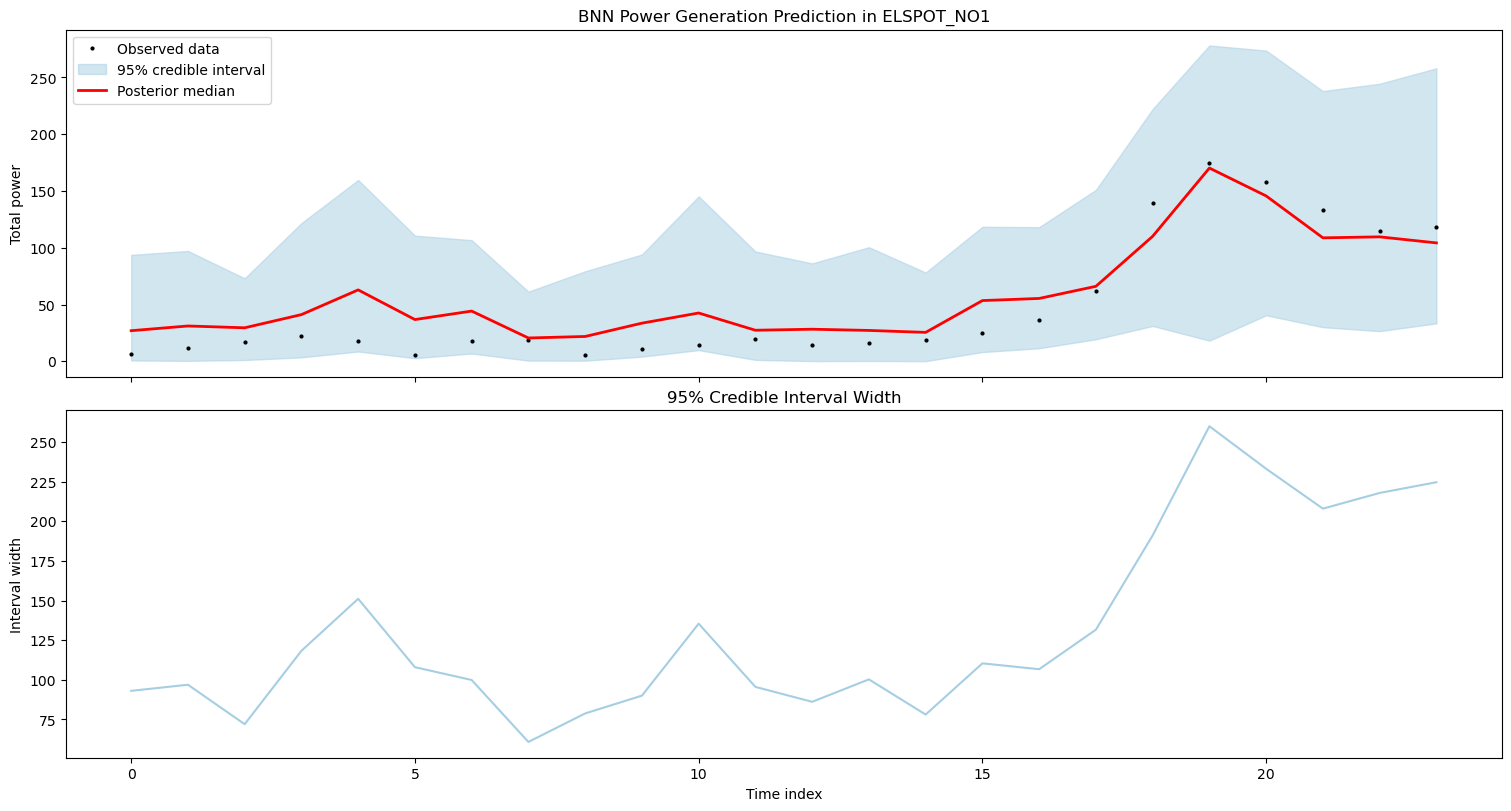

In [20]:
fig, axes = plt.subplots(nrows=2, figsize=(15, 8), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(
    eval_data["Y_eval_gen"],
    ".",
    color="black",
    label="Observed data",
    markersize=4,
)

ax.fill_between(
    np.arange(24),
    forecast_extended[i]["hdi_lower"].values,
    forecast_extended[i]["hdi_upper"].values,
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(
    forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
)

ax.set(
    ylabel="Total power",
    title=f"BNN Power Generation Prediction in {bid_zone}",
)
ax.legend()


# Compute interval width
width = (
    forecast_extended[i]["hdi_upper"].values - forecast_extended[i]["hdi_lower"].values
)
ax2 = axes[1]
ax2.plot(width, color="#A6CEE3")
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)

plt.show()